In [51]:
#[2 points –Project description
#1 point –Using a dataframe with any useful functions such as info() and describe()
#1 point – Visualizing the dataset
#3 points – Preprocessing – feature scaling 
#4 points – Splitting the data into training and testing] - Matthew

#[5 points- Using a classification model
#4 points- Precision/Recall/Confusion matrix and The ROC Curve of the model] - Emerson


#10 points -  Jupyter Notebook with complete code and comments for each cell (do not have all code in one cell. Put comments for each cell) -both


In [52]:
#THIS PROJECT WILL CREATE A CLASSIFICATION SYSTEM FOR IDENTIFYING WHO DID AND DID NOT SURVIVE THE TITANIC BASED ON
#INFORMATION GATHERED ON EACH INDIVIDUAL PASSENGER, FOLLOWED BY TESTING FOR HOW ACCURATE THE SYSTEM IS

In [53]:
#CREATE DATA FRAME WITH DATA FROM TITANIC.CSV
import pandas as pd
titanic = pd.read_csv("titanic.csv")

In [54]:
#VIEW ALL KEYS AND DATA TYPES OF CATEGORIES FOR DATA
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [55]:
#VIEW ACTUAL DATA WITHIN THOSE CATEGORIES
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [56]:
#VIEW NUMERIC INFORMATION RELATING TO EACH NUMERIC CATEGORY
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


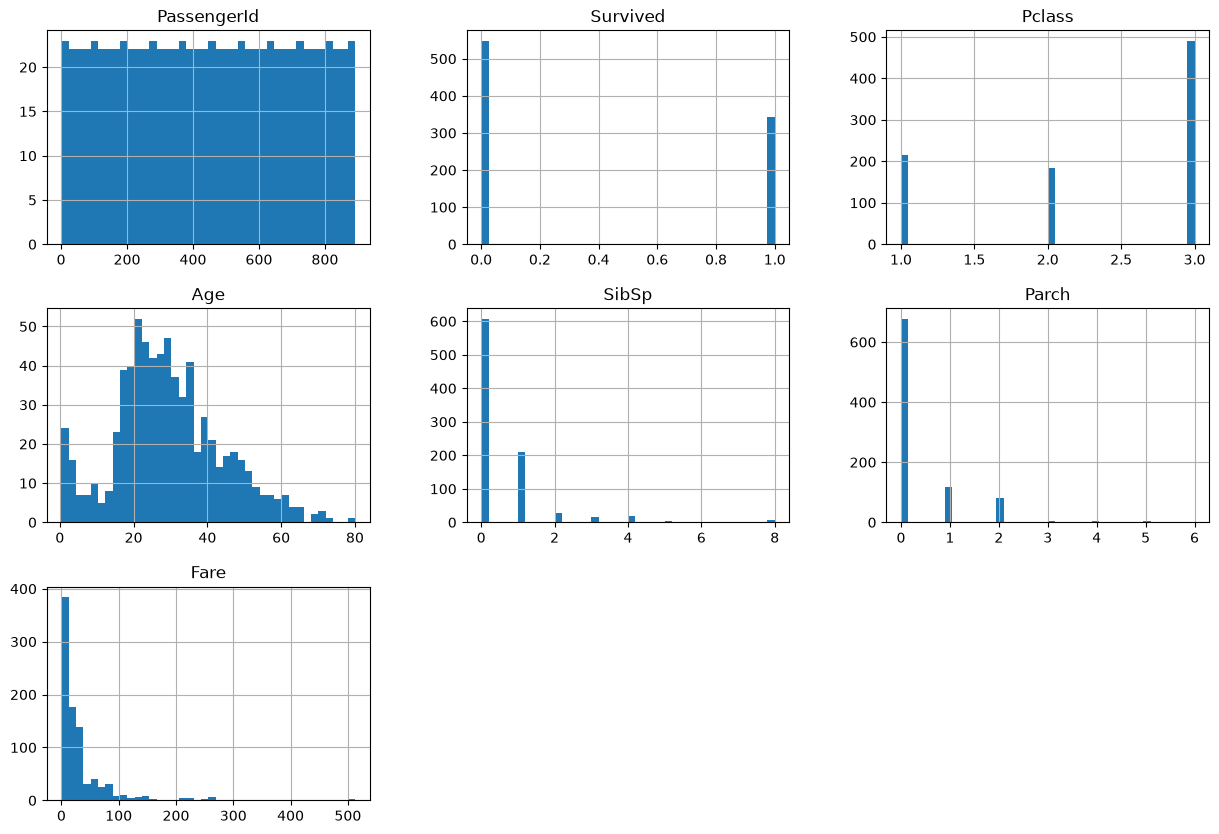

In [57]:
#VISUALIZE DATA THROUGH GRAPHS OF NUMERIC CATEGORY
%matplotlib inline
import matplotlib.pyplot as plt
titanic.hist(bins=40, figsize=(15,10))
plt.show()

In [58]:
#CREATE VARIABLE TO HOLD EVERYTHING FROM TITANIC DATA EXCEPT FOR WHO SURVIVED
#SECOND VARIABLE ONLY HOLDS THE RESULTS OF WHO SURVIVED
x = titanic.drop("Survived", axis=1)
y = titanic["Survived"]
#x["Survived"].value_counts() (doesn't work, used for proof of not having this category)

In [59]:
#NUM_PIPELINE TAKES MISSING NUMERIC VALUES AND FILLS MISSING DATA WITH MEDIAN VALUES
#NUM_PIPELINE SCALES NUMERIC VALUES SO NO VALUE IS SKEWED 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [60]:
#CREATES FULL PIPELINE THAT CAN HANDLE NUMERIC AND NON NUMERIC CATEGORIES
#NON NUMERIC VALUES ARE INCLUDED BY BEING CONVERTED INTO NUMERIC CATEGORIES WITH VALUES OF 0 OR 1 
#TITANIC_PREPARED FOLLOWS THE PIPELINE RULES AND APPLIES IT ON X
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

num_attribs = ["Age", "SibSp", "Parch", "Fare"]
cat_attribs = ["Pclass", "Sex", "Embarked"]

full_pipeline = ColumnTransformer([
        ("num", num_pipeline, num_attribs),
        ("cat", OneHotEncoder(), cat_attribs),
    ])

titanic_prepared = full_pipeline.fit_transform(x)

In [61]:
#VIEW SIZE OF DATA SET TO CONFIRM IT WORKED, 891 ENTRIES WITH 13 CATEGORIES
titanic_prepared.shape


(891, 13)

In [62]:
#VIEW VALUES IN DATA, IT IS SCALED AND ALL NUMERIC
titanic_prepared

array([[-0.56573646,  0.43279337, -0.47367361, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.66386103,  0.43279337, -0.47367361, ...,  0.        ,
         0.        ,  0.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [-0.1046374 ,  0.43279337,  2.00893337, ...,  0.        ,
         1.        ,  0.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.20276197, -0.4745452 , -0.47367361, ...,  1.        ,
         0.        ,  0.        ]], shape=(891, 13))

In [63]:
#CHECK WHAT 80% OF SET WOULD BE
print(891 * 0.8)

712.8000000000001


In [64]:
#CREATE TRAINING SET WITH FIRST 80% OF DATA AND STORE THE ANSWERS TO THE DATA IN Y VARIABLE
#DO THE SAME FOR TESTING SET BUT WITH LAST 20% OF THE DATA INSTEAD
x_train = titanic_prepared[:712]
y_train = y[:712]

x_test = titanic_prepared[712:]
y_test = y[712:]


In [65]:
#End of Matthew work

In [66]:
#Start of Emerson Work

In [67]:
#CHOOSE A CLASSIFICATION MODEL (SGDClassifier)
#Fit the data into the classifier model
from sklearn.linear_model import SGDClassifier

classified = SGDClassifier(random_state=42)
classified.fit(x_train, y_train)


,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [68]:
#USE X_TEST TO PREDICT THE BINARY CLASSIFICATION
classified.predict(x_test)

array([0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0])

In [69]:
#FIND OUT THE CROSS VALUE SCORE FOR THE MODEL
from sklearn.model_selection import cross_val_score
cross_val_score(classified, x_train, y_train, cv=3, scoring="accuracy")

array([0.74789916, 0.74683544, 0.67088608])

In [70]:
#USE CROSS VALIDATION TO PREDICT A Y VALUE
from sklearn.model_selection import cross_val_predict

y_predict = cross_val_predict(classified, x_train, y_train, cv=3)

In [71]:
#CREATE CONFUSION MATRIX
from sklearn.metrics import confusion_matrix
confusion_matrix(y_train, y_predict)


array([[362,  72],
       [126, 152]])

In [72]:
#IMPORT RECALL AND PRECISION AND PERFORM PRECISION CALCULATIONS
from sklearn.metrics import precision_score, recall_score
#using the precision_score function
precision_score(y_train, y_predict)

0.6785714285714286

In [73]:
#calulating based on confusion matrix
matrix = confusion_matrix(y_train, y_predict)
matrix[1, 1] / (matrix[0, 1] + matrix[1, 1])

np.float64(0.6785714285714286)

In [74]:
#DO RECALL CALCULATION USING RECALL_SCORE FUNCTION
recall_score(y_train, y_predict)

0.5467625899280576

In [75]:
#calculate based on confusion matrix
matrix[1, 1] / (matrix[1, 0] + matrix[1, 1])

np.float64(0.5467625899280576)

In [78]:
#Set up recall/precision trade-off
y_scores = cross_val_predict(classified, x_train, y_train, cv=3, method="decision_function")
y_scores

array([-9.23629698e+00,  1.13288562e+01,  9.05873824e-02,  5.44304544e+00,
       -7.11995854e+00, -6.00154303e+00,  1.29219436e-01, -1.28784896e+01,
        1.97687465e-01,  7.68953795e+00, -2.46574095e+00,  7.82055802e+00,
       -8.07072132e+00, -7.83140416e+00, -6.70987549e-01,  5.93011111e+00,
       -1.24937033e+01, -3.60484634e+00, -7.36654321e-01,  5.65571242e+00,
       -2.98402066e+00, -3.22454123e+00,  9.51322530e-01, -1.74172277e+00,
       -4.71547766e+00, -1.10548612e-01, -2.12699441e+00, -3.05662364e+00,
        1.77327305e+00, -7.56574895e+00,  4.36078382e+00,  1.17201912e+01,
        1.77151259e+00, -1.23031200e+00,  3.06065921e+00, -1.91096055e+00,
       -2.12693718e+00, -8.00733713e+00, -2.84209205e+00,  3.54162156e+00,
       -2.82357249e-01,  2.94203998e+00, -2.11785417e+00,  7.14912395e+00,
        1.20281539e+00, -7.56364784e+00, -7.18703703e+00,  1.77151259e+00,
       -4.49292993e+00, -1.56337390e+00, -1.35894004e+01, -8.01074360e+00,
        1.21002874e+01,  

In [79]:
#USE THE Y_SCORES TO FIND THE ROC CURVE
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train, y_scores)

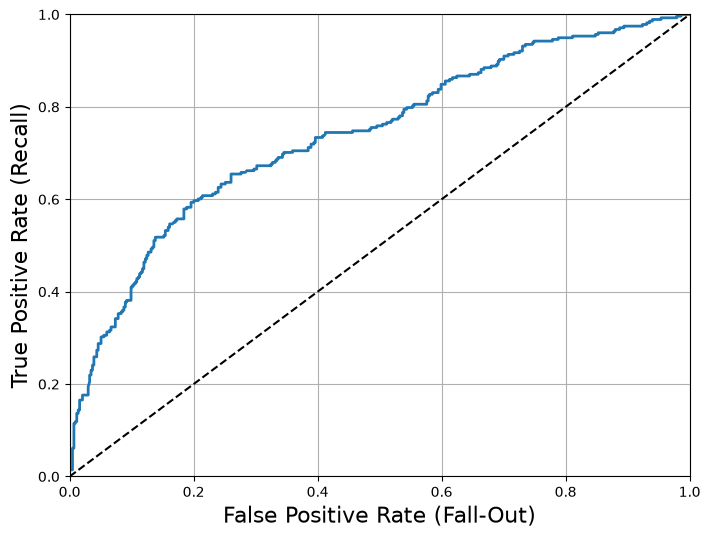

In [84]:
#PLOT THE ROC LINE USING THE FPR, TPR, and THRESHOLDS 
import numpy as np
#SET UP THE GRAPH
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])                                   
    plt.xlabel('False Positive Rate (Fall-Out)', fontsize=16) 
    plt.ylabel('True Positive Rate (Recall)', fontsize=16)    
    plt.grid(True)                                           

plt.figure(figsize=(8, 6))                                   
plot_roc_curve(fpr, tpr)                                  
plt.show()

In [82]:
#USE Y_TRAIN AND Y_SCORES TO FIND THE ROC AUC SCORE
from sklearn.metrics import roc_auc_score

roc_auc_score(y_train, y_scores)

0.7395484534031761